# Tropical-cyclone projections: CMIP6-HighResMIP

How the number of tropical cyclones (TCs) forming in each Pacific subregion, and the latitude where they form, may change by mid-century. Global models at standard resolution do not represent TCs well, so this notebook uses the TC tracks detected in the **CMIP6-HighResMIP high-resolution atmosphere-only models** (25–75 km), with the set-up of [Li & Zhou (2024)](https://doi.org/10.1038/s41612-024-00704-3):

* four models: CMCC-CM2-VHR4, CNRM-CM6-1-HR, EC-Earth3P-HR and HadGEM3-GC31-HM (all their ensemble members);
* two TC trackers: TRACK (Hodges et al., 2017) and TempestExtremes (Zarzycki & Ullrich, 2017); CMCC has no TempestExtremes tracks;
* present 1980–2010 (`highresSST-present`, observed SST) vs future 2020–2050 (`highresSST-future`, SSP5-8.5).

A storm counts as a TC from the first track point with a 10-m wind of at least 34 kt (its **genesis**). Each TC is assigned to the subregion where it forms, using the same four boxes as the [historical regional notebook](../../../historical/Regional/tropical_cyclones/regional_indicators.ipynb). Observed counts for 1980–2010 come from IBTrACS with the same definition.

```{glue:figure} tc_counts_fig
:scale: 60%
:align: center
```

**Figure. Tropical cyclones forming per year in each Pacific subregion**: multi-model mean for 1980–2010 and 2020–2050 (SSP5-8.5) for each tracker, each model as a marker, and the observed 1980–2010 mean (dashed line).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Track download, genesis extraction, indicators and figures come from `functions/tc_projections.py`; the subregions from `functions/tcs.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../functions")
import projections as prj
import tc_projections as tp

### Configuration

Figures go to `outputs/figures/regional_pacific/PRJ_TC_*` and tables to `outputs/tables/regional_pacific/PRJ_TC_*`.

In [3]:
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)
ibtracs_file = Path("../../../../data/tcs/tcs_ALL.nc")  # all-basin IBTrACS cache of the historical regional notebook

def save(fig, name):
    fig.savefig(fig_dir / f"PRJ_TC_{name}_pacific.png", dpi=150, bbox_inches="tight")

def save_table(df, name, index=False):
    df.to_csv(tables_dir / f"PRJ_TC_{name}_pacific.csv", index=index)

## HighResMIP tracks and constrained detection

`tp.load_genesis()` lists the members available on CEDA, downloads each track file (northern and southern hemisphere, about 50 MB each, ~3 GB in total) to a temporary folder, keeps one row per storm reaching 34 kt and deletes the file. The small genesis tables are cached in `data/projections/regional/tcs_highresmip/`, so later runs do not download anything.

Models tend to detect extratropical storms as TCs, especially in winter and spring. Following Li & Zhou (2024), storms are removed when they form over land or poleward of a monthly latitude limit, set south of the westerlies and north of the 26 °C isotherm: 20° in December–March, 25° in April, May and November, 30° in June and October, 35° in July–September. Li & Zhou define these limits for the northern hemisphere; in the southern hemisphere the same limits are applied six months later (35°S in January–March, 20°S in June–September). The table gives the members used and the share of storms removed.

**Archive quality control.** Two problems were found in the CEDA files and are handled automatically: storms stored twice in a file are counted once (EC-Earth3P-HR TempestExtremes, future, member r1i1p1f1), and members whose tracks cover less than 80 % of the period's years are excluded (EC-Earth3P-HR TempestExtremes, future, r2i1p1f1, whose time axis restarts every year). Counts are divided by the years each member actually covers (the EC-Earth3P-HR r1i1p1f1 future files end in 2049). The second table lists every member.

In [4]:
genesis, qc = tp.load_genesis(return_qc=True)

removed = genesis.groupby(["tracker", "model"]).agg(over_land=("over_land", "mean"), not_kept=("kept", lambda k: 1 - k.mean()))
removed["too_poleward"] = removed["not_kept"] - removed["over_land"]
members = qc.loc[qc["used"]].groupby(["tracker", "model", "period"])["member"].nunique().unstack("period")[["present", "future"]]
detection = members.join((removed[["over_land", "too_poleward"]] * 100).round(1)).rename(
    columns={"present": "Members 1980–2010", "future": "Members 2020–2050",
             "over_land": "Removed: over land (%)", "too_poleward": "Removed: too poleward (%)"})
save_table(detection.reset_index(), "highresmip_detection")
save_table(qc, "highresmip_member_qc")
display(detection)
qc


TRACK   CMCC-CM2-VHR4    present r1i1p1f1


TRACK   CMCC-CM2-VHR4    future  r1i1p1f1


TRACK   CNRM-CM6-1-HR    present r1i1p1f2


TRACK   CNRM-CM6-1-HR    future  r1i1p1f2


TRACK   EC-Earth3P-HR    present r1i1p1f1
TRACK   EC-Earth3P-HR    present r2i1p1f1
TRACK   EC-Earth3P-HR    present r3i1p1f1


TRACK   EC-Earth3P-HR    future  r1i1p1f1
TRACK   EC-Earth3P-HR    future  r2i1p1f1
TRACK   EC-Earth3P-HR    future  r3i1p1f1
TRACK   HadGEM3-GC31-HM  present r1i1p1f1


... (5 outputs left out)

TempExt HadGEM3-GC31-HM  present r1i1p1f1
TempExt HadGEM3-GC31-HM  present r1i2p1f1
TempExt HadGEM3-GC31-HM  present r1i3p1f1


TempExt HadGEM3-GC31-HM  future  r1i1p1f1
TempExt HadGEM3-GC31-HM  future  r1i2p1f1
TempExt HadGEM3-GC31-HM  future  r1i3p1f1
Excluded: TempExt EC-Earth3P-HR future r2i1p1f1 (0/31 years)


Members 1980–2010  Members 2020–2050  \
tracker model                                                   
TRACK   CMCC-CM2-VHR4                    1                  1   
        CNRM-CM6-1-HR                    1                  1   
        EC-Earth3P-HR                    3                  3   
        HadGEM3-GC31-HM                  3                  3   
TempExt CNRM-CM6-1-HR                    1                  1   
        EC-Earth3P-HR                    3                  2   
        HadGEM3-GC31-HM                  3                  3   

                         Removed: over land (%)  Removed: too poleward (%)  
tracker model                                                               
TRACK   CMCC-CM2-VHR4                       6.8                       14.6  
        CNRM-CM6-1-HR                       4.6                       25.6  
        EC-Earth3P-HR                       3.1                       28.3  
        HadGEM3-GC31-HM                     4.3                       15.8  
TempExt CNRM-CM6-1-HR                       4.1                        9.4  
        EC-Earth3P-HR                       1.5                        4.3  
        HadGEM3-GC31-HM                     3.4                        5.8

,tracker,model,period,member,storms,duplicates_removed,years_covered,years_in_period,used
0,TRACK,CMCC-CM2-VHR4,present,r1i1p1f1,4229,0,31,31,True
1,TRACK,CMCC-CM2-VHR4,future,r1i1p1f1,3969,0,31,31,True
2,TRACK,CNRM-CM6-1-HR,present,r1i1p1f2,4160,0,31,31,True
3,TRACK,CNRM-CM6-1-HR,future,r1i1p1f2,3836,0,31,31,True
4,TRACK,EC-Earth3P-HR,present,r1i1p1f1,2026,0,31,31,True
5,TRACK,EC-Earth3P-HR,present,r2i1p1f1,2054,0,31,31,True
6,TRACK,EC-Earth3P-HR,present,r3i1p1f1,1996,0,31,31,True
7,TRACK,EC-Earth3P-HR,future,r1i1p1f1,1910,0,30,31,True
8,TRACK,EC-Earth3P-HR,future,r2i1p1f1,1920,0,31,31,True
9,TRACK,EC-Earth3P-HR,future,r3i1p1f1,1984,0,31,31,True


## Observed reference (IBTrACS)

IBTrACS storms that reach 34 kt (WMO wind) and form in each subregion, 1980–2010, with the same genesis definition. The historical notebook counts every storm crossing a box; here each TC is counted once, in the box where it forms, so the numbers differ slightly from those of the historical analysis.

In [5]:
ibtracs = xr.load_dataset(ibtracs_file)
observed_genesis = tp.observed_genesis(ibtracs, 1980, 2010)
observed = tp.observed_counts(observed_genesis)
observed.round(2).to_frame("Observed TCs per year, 1980–2010")

,"Observed TCs per year, 1980–2010"
region,
Western North Pacific,20.23
Central North Pacific,1.16
Western South Pacific,6.74
Central South Pacific,3.42


## Number of tropical cyclones

Mean number of TCs forming per year in each subregion, for every model (mean of its members) and the multi-model mean of each tracker (models weighted equally), and the % change from 1980–2010 to 2020–2050. The summary table gives the multi-model mean, the range across models and how many models project a decrease.

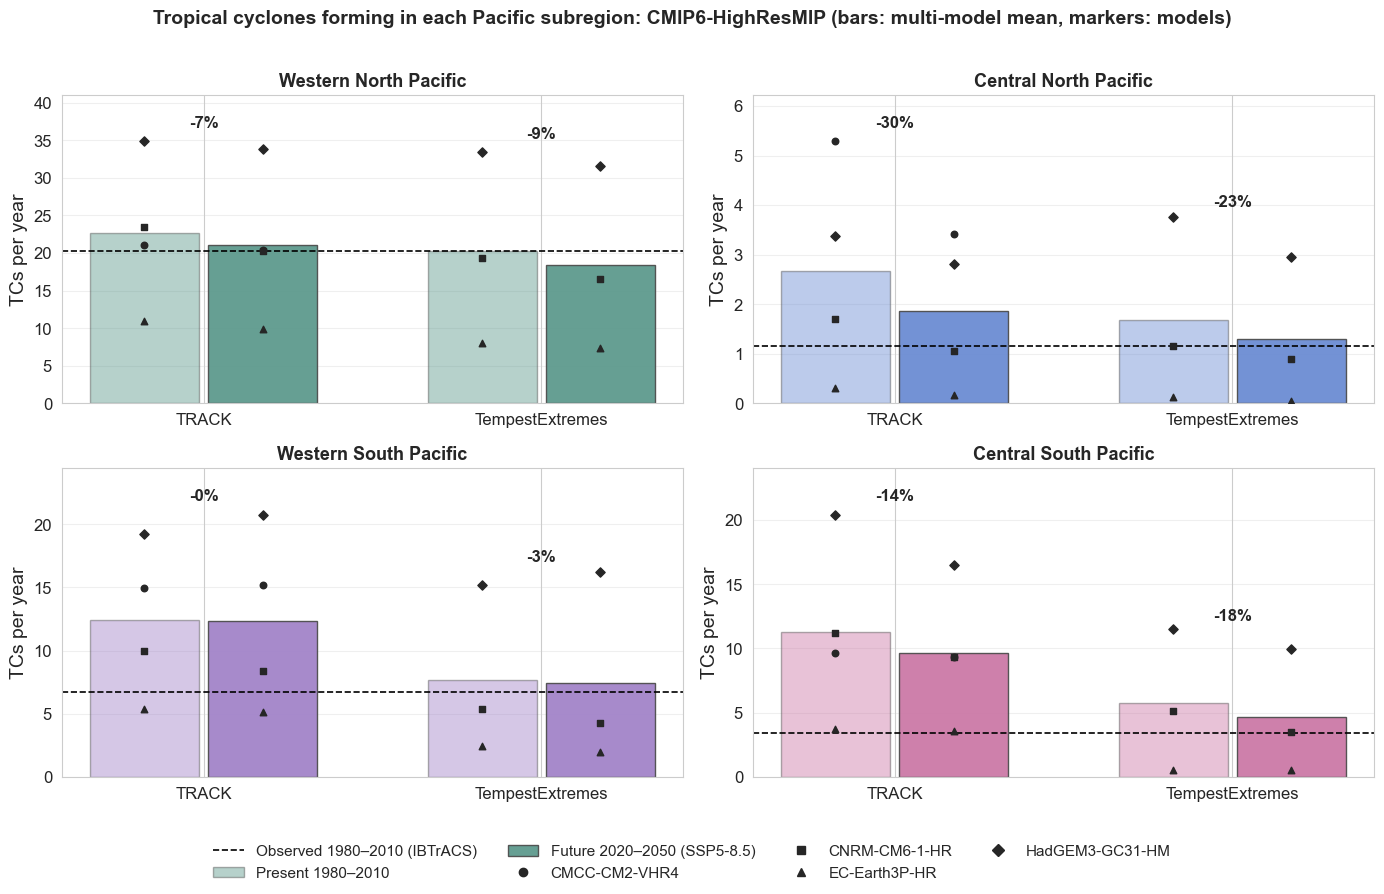

,Region,Tracker,Observed 1980–2010 (TCs/yr),Present 1980–2010 (TCs/yr),Future 2020–2050 (TCs/yr),Change (%),Model range (%),Models with decrease
0,Western North Pacific,TRACK,20.2,22.6,21.1,-6.6,-14 to -3,4/4
1,Central North Pacific,TRACK,1.2,2.7,1.9,-30.1,-44 to -17,4/4
2,Western South Pacific,TRACK,6.7,12.4,12.4,-0.3,-16 to +8,2/4
3,Central South Pacific,TRACK,3.4,11.3,9.7,-14.0,-19 to -3,4/4
4,Western North Pacific,TempestExtremes,20.2,20.3,18.4,-9.1,-15 to -6,3/3
5,Central North Pacific,TempestExtremes,1.2,1.7,1.3,-22.5,-58 to -21,3/3
6,Western South Pacific,TempestExtremes,6.7,7.7,7.5,-2.6,-21 to +7,2/3
7,Central South Pacific,TempestExtremes,3.4,5.7,4.7,-18.5,-32 to -9,3/3


In [6]:
change = tp.count_change(genesis)
summary = tp.summary_table(change, observed)
save_table(change.round(2), "count_change_highresmip")
save_table(summary, "count_summary_highresmip")

fig = tp.plot_counts(change, observed)
save(fig, "counts_highresmip")
glue("tc_counts_fig", fig, display=False)
plt.show()
summary

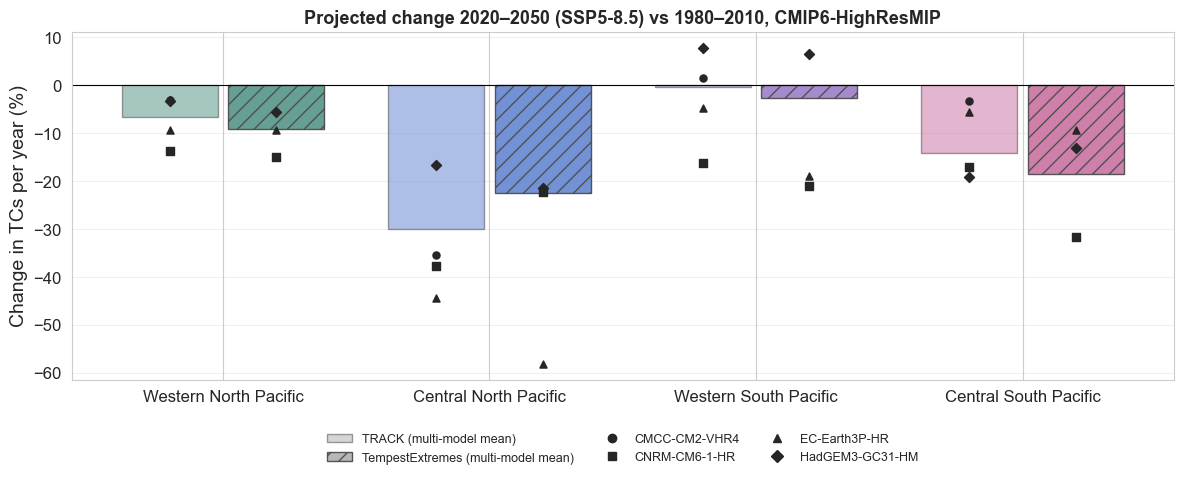

In [7]:
fig = tp.plot_change(change)
save(fig, "count_change_highresmip")
plt.show()

## Poleward shift of genesis latitude

Change in the mean latitude where TCs form (absolute latitude, so positive values are poleward in both hemispheres), per model and multi-model mean, for the whole year and for the peak season of each hemisphere (June–October in the north, December–April in the south). The same is shown for the latitude of lifetime maximum intensity (LMI).

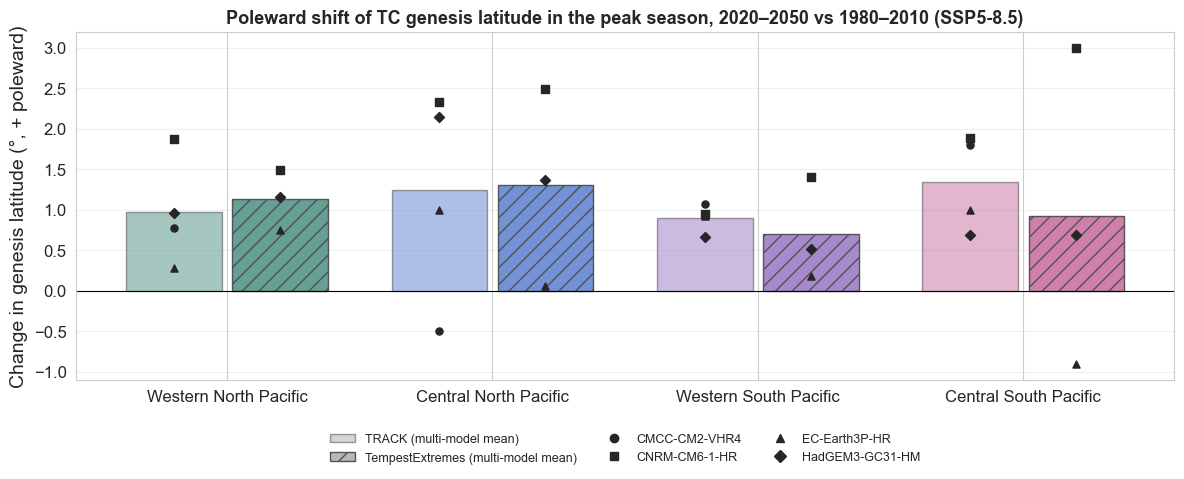

region                                Western North Pacific  \
Latitude Season      Tracker                                  
Genesis  Annual      TRACK                             0.76   
                     TempestExtremes                   0.94   
         Peak season TRACK                             0.97   
                     TempestExtremes                   1.13   
LMI      Annual      TRACK                             0.22   
                     TempestExtremes                   0.39   
         Peak season TRACK                             0.59   
                     TempestExtremes                   0.58   

region                                Central North Pacific  \
Latitude Season      Tracker                                  
Genesis  Annual      TRACK                             1.35   
                     TempestExtremes                   2.38   
         Peak season TRACK                             1.25   
                     TempestExtremes                   1.31   
LMI      Annual      TRACK                             0.70   
                     TempestExtremes                   2.49   
         Peak season TRACK                             0.67   
                     TempestExtremes                   1.41   

region                                Western South Pacific  \
Latitude Season      Tracker                                  
Genesis  Annual      TRACK                             0.92   
                     TempestExtremes                   0.75   
         Peak season TRACK                             0.90   
                     TempestExtremes                   0.70   
LMI      Annual      TRACK                             1.25   
                     TempestExtremes                   1.57   
         Peak season TRACK                             1.31   
                     TempestExtremes                   1.56   

region                                Central South Pacific  
Latitude Season      Tracker                                 
Genesis  Annual      TRACK                             1.30  
                     TempestExtremes                   0.89  
         Peak season TRACK                             1.34  
                     TempestExtremes                   0.93  
LMI      Annual      TRACK                             1.15  
                     TempestExtremes                  -0.21  
         Peak season TRACK                             0.75  
                     TempestExtremes                  -0.26

In [8]:
nh_peak, sh_peak = [6, 7, 8, 9, 10], [12, 1, 2, 3, 4]
nh_regions, sh_regions = list(tp.REGIONS[:2]), list(tp.REGIONS[2:])

def by_season(column):
    peak_nh = tp.latitude_change(genesis, months=nh_peak, column=column)
    peak_sh = tp.latitude_change(genesis, months=sh_peak, column=column)
    peak = peak_nh[["Tracker", "Model"] + nh_regions].merge(peak_sh[["Tracker", "Model"] + sh_regions], on=["Tracker", "Model"])
    annual = tp.latitude_change(genesis, column=column)
    return pd.concat([annual.assign(Season="Annual"), peak.assign(Season="Peak season")], ignore_index=True)

lat_change = pd.concat([by_season("lat").assign(Latitude="Genesis"), by_season("lmi_lat").assign(Latitude="LMI")], ignore_index=True)
save_table(lat_change.round(2), "latitude_change_highresmip")

peak_genesis = lat_change.query("Latitude == 'Genesis' and Season == 'Peak season'").drop(columns=["Latitude", "Season"])
fig = tp.plot_change(tp.latitude_change_long(peak_genesis), value="Poleward shift (°)",
                     ylabel="Change in genesis latitude (°, + poleward)",
                     title="Poleward shift of TC genesis latitude in the peak season, 2020–2050 vs 1980–2010 (SSP5-8.5)")
save(fig, "genesis_latitude_change_highresmip")
plt.show()

lat_change.query("Model == 'Multi-model mean'").set_index(["Latitude", "Season", "Tracker"]).drop(columns="Model").round(2)

### Check against Li & Zhou (2024)

Li & Zhou report a June–October genesis shift of +1.13° (TRACK) and +1.16° (TempestExtremes) over the whole western North Pacific, which includes the South China Sea. The same calculation for storms forming at 100–180°E in the northern hemisphere should give similar values; differences come from the members averaged and small details of the genesis definition.

In [9]:
wnp = genesis.loc[genesis["kept"] & (genesis["hemisphere"] == "NH") & genesis["lon"].between(100, 180)
                  & genesis["month"].between(6, 10)]
wnp_lat = wnp.groupby(["tracker", "model", "period"])["lat"].mean().unstack("period")
wnp_shift = (wnp_lat["future"] - wnp_lat["present"]).unstack("tracker").rename(columns=tp.TRACKER_LABEL)
wnp_shift.loc["Multi-model mean"] = wnp_shift.mean()
wnp_shift.round(2).rename_axis(columns="WNP (100–180°E) JJASO genesis shift (°)")

WNP (100–180°E) JJASO genesis shift (°),TRACK,TempestExtremes
model,,
CMCC-CM2-VHR4,0.74,NaN
CNRM-CM6-1-HR,1.54,1.22
EC-Earth3P-HR,0.44,0.87
HadGEM3-GC31-HM,0.93,1.07
Multi-model mean,0.91,1.05


## Track latitude and track density

Where the models' TCs travel, not only where they form: the change in the mean latitude of all track points at TC strength (≥ 34 kt) of the storms forming in each subregion, and the map of the change in track density (TC days per year per 2.5° cell, multi-model mean). Track densities are computed for every member (6-hourly track points of the constrained TCs), which needs the full track files: `tp.load_tracks()` downloads them the first time and caches only the small density grids (`*_tracks.npz`).

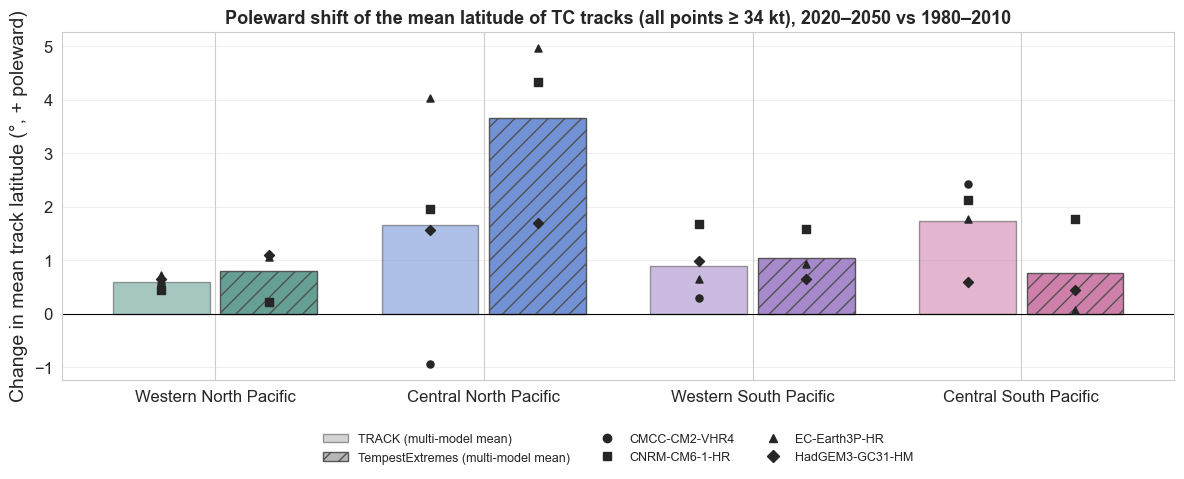

Western North Pacific  \
                 Tracker                                  
Genesis latitude TRACK                             0.76   
                 TempestExtremes                   0.94   
Track latitude   TRACK                             0.59   
                 TempestExtremes                   0.79   

                                  Central North Pacific  \
                 Tracker                                  
Genesis latitude TRACK                             1.35   
                 TempestExtremes                   2.38   
Track latitude   TRACK                             1.65   
                 TempestExtremes                   3.67   

                                  Western South Pacific  Central South Pacific  
                 Tracker                                                        
Genesis latitude TRACK                             0.92                   1.30  
                 TempestExtremes                   0.75                   0.89  
Track latitude   TRACK                             0.90                   1.73  
                 TempestExtremes                   1.04                   0.76

In [10]:
density, track_lat = tp.load_tracks(qc, verbose=False)

track_shift = tp.track_latitude_change(track_lat)
save_table(track_shift.round(2), "track_latitude_change_highresmip")
fig = tp.plot_change(tp.latitude_change_long(track_shift), value="Poleward shift (°)",
                     ylabel="Change in mean track latitude (°, + poleward)",
                     title="Poleward shift of the mean latitude of TC tracks (all points ≥ 34 kt), 2020–2050 vs 1980–2010")
save(fig, "track_latitude_change_highresmip")
plt.show()

genesis_annual = lat_change.query("Latitude == 'Genesis' and Season == 'Annual' and Model == 'Multi-model mean'")
pd.concat({"Genesis latitude": genesis_annual.set_index("Tracker")[list(tp.REGIONS)],
           "Track latitude": track_shift.query("Model == 'Multi-model mean'").set_index("Tracker")[list(tp.REGIONS)]}).round(2)

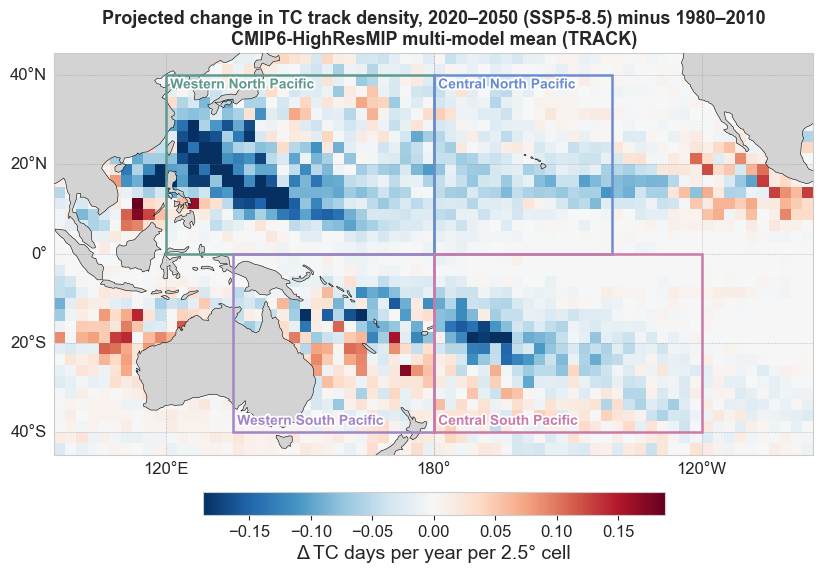

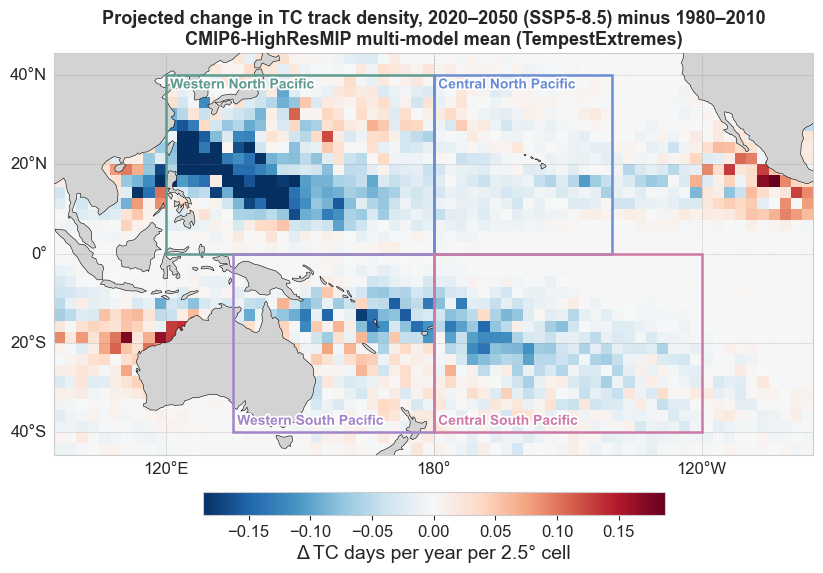

In [11]:
for tracker in tp.TRACKERS:
    fig = tp.plot_density_change(density, tracker)
    save(fig, f"density_change_{tracker}_highresmip")
    plt.show()

The genesis latitude rises by about +0.7 to +1.3° in the peak season in all four subregions; the tracks as a whole move less in the Western North Pacific (+0.6 to +0.8°) and more, but with a large spread between models, in the Central North and Central South Pacific. The track-density maps show where this comes from: a broad decrease of TC activity along the main tracks (Philippine Sea and South China Sea, central South Pacific) and little increase further poleward. Over 31 years the map is noisy cell by cell (internal variability is large at 2.5°), so it is best read for its large-scale pattern.

## Seasonal cycle

Multi-model mean number of TCs forming in each month, 1980–2010 vs 2020–2050, for each tracker.

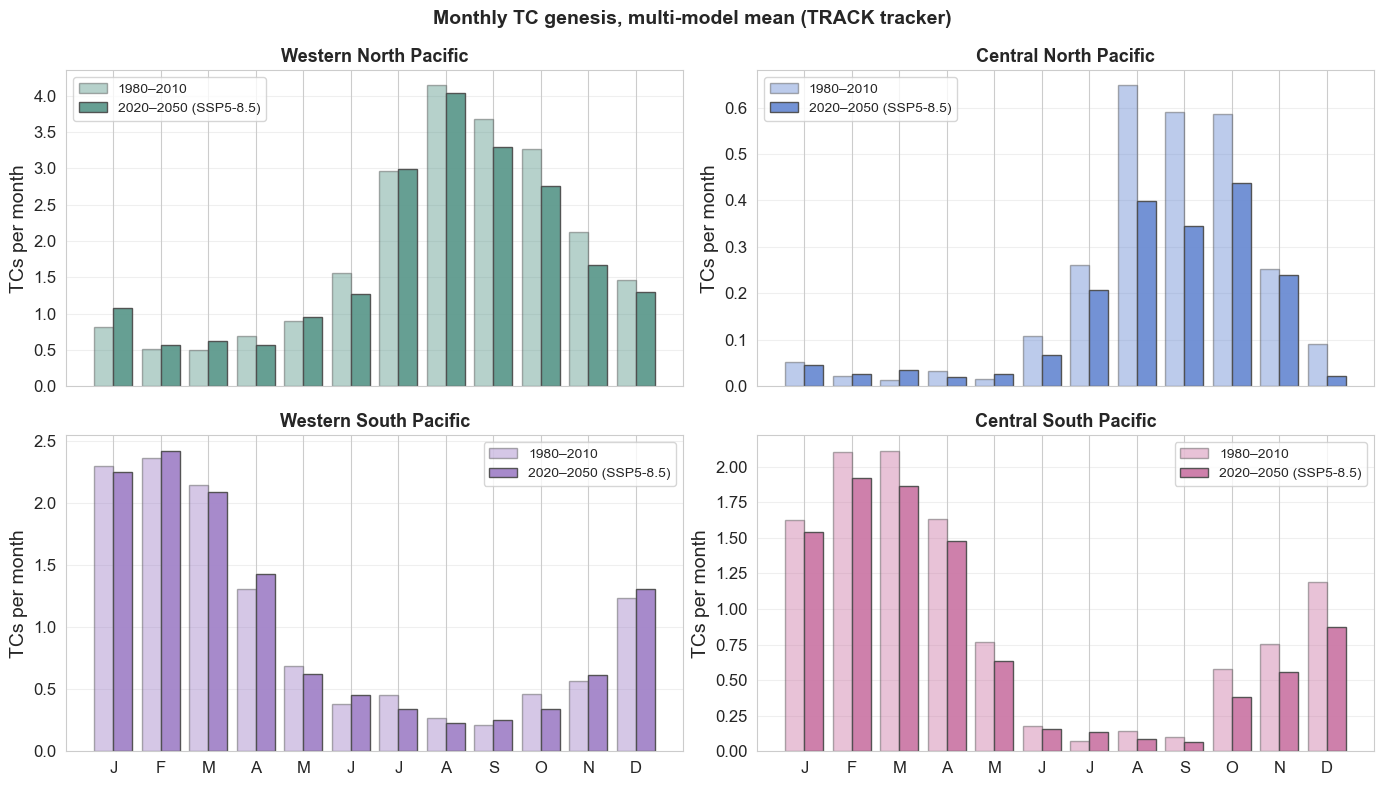

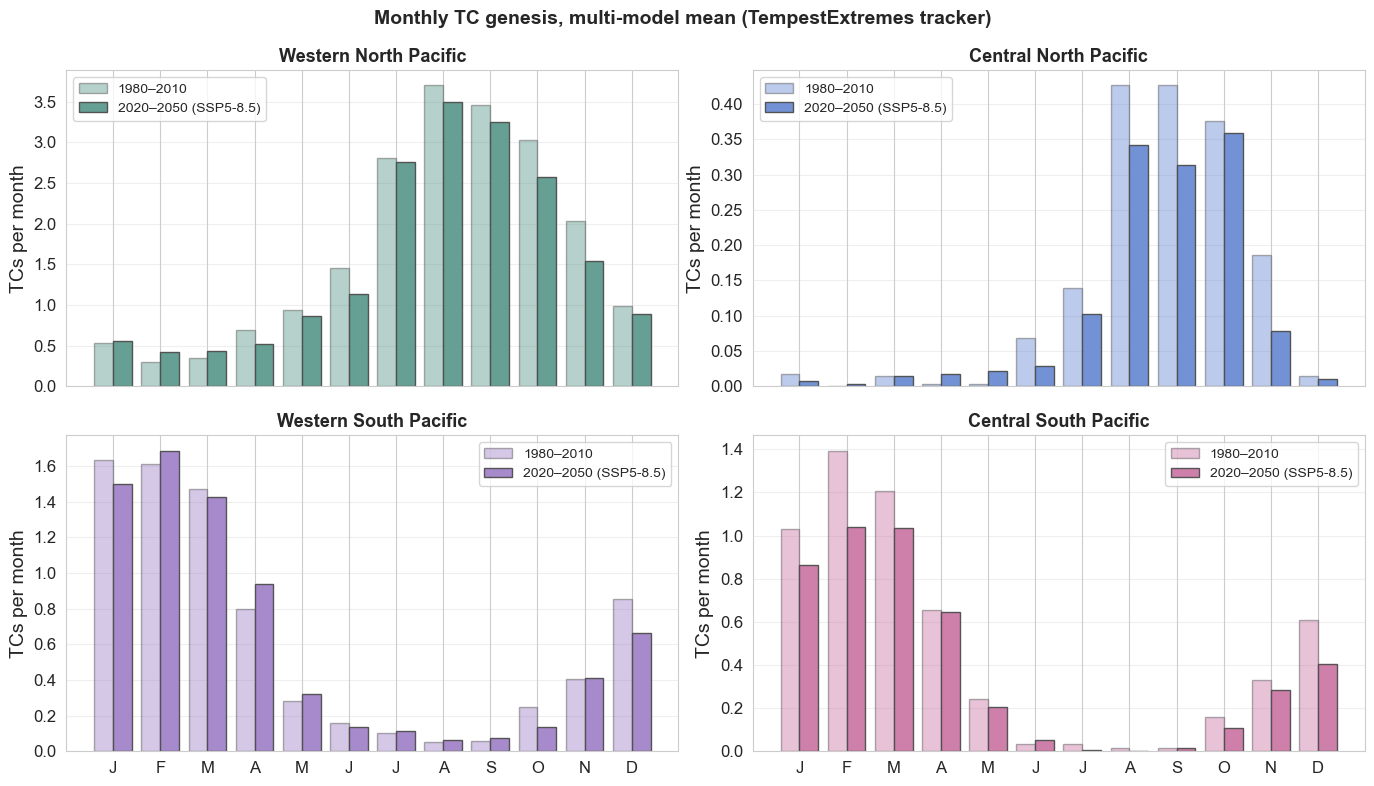

In [12]:
cycle = tp.monthly_cycle(genesis)
for tracker in tp.TRACKERS:
    fig = tp.plot_monthly_cycle(cycle, tracker)
    save(fig, f"monthly_genesis_{tracker}_highresmip")
    plt.show()

## Interpretation and reproducibility notes

- **Scenario and horizon:** the future period is 2020–2050 under SSP5-8.5, the only future experiment of the HighResMIP atmosphere-only runs; changes by the end of the century or under other scenarios are not available from this ensemble.
- **Small ensemble:** four models (three with TempestExtremes); the model range and the number of models agreeing on the sign matter as much as the mean.
- **Tracker dependence:** TRACK and TempestExtremes detect different storms; results are shown for both.
- **Model bias:** compare the present-day counts with IBTrACS before using the % changes. Models typically miss or overcount TCs in some subregions; the % change is more robust than the absolute numbers.
- **Constrained detection:** the monthly latitude limits remove extratropical storms (Li & Zhou, 2024); the southern-hemisphere limits are a CIndRA adaptation (northern limits shifted by six months).
- **Intensity:** the 25–75 km models underestimate the strongest winds, so only the number of TCs reaching 34 kt is analysed, not their category.
- **Prescribed SST:** the atmosphere-only runs use observed SST for 1980–2010 and SST warmed according to SSP5-8.5 for the future; ocean–atmosphere feedbacks are not included.

**References**

- Li, Z. & Zhou, W. (2024). Poleward migration of tropical cyclones over the western North Pacific in the CMIP6-HighResMIP models constrained by observations. *npj Climate and Atmospheric Science* 7, 161. [doi:10.1038/s41612-024-00704-3](https://doi.org/10.1038/s41612-024-00704-3)
- Roberts, M. J. et al. (2020). Impact of model resolution on tropical cyclone simulation using the HighResMIP–PRIMAVERA multimodel ensemble. *Journal of Climate* 33, 2557–2583. [doi:10.1175/JCLI-D-19-0639.1](https://doi.org/10.1175/JCLI-D-19-0639.1)
- Roberts, M. J. (2019). CMIP6 HighResMIP: tropical storm tracks as calculated by the TRACK algorithm / the TempestExtremes algorithm. Centre for Environmental Data Analysis. [TRACK](https://catalogue.ceda.ac.uk/uuid/0b42715a7a804290afa9b7e31f5d7753), [TempestExtremes](https://catalogue.ceda.ac.uk/uuid/438268b75fed4f27988dc02f8a1d756d) (CC BY 4.0).
- Hodges, K., Cobb, A. & Vidale, P. L. (2017). How well are tropical cyclones represented in reanalysis datasets? *Journal of Climate* 30, 5243–5264.
- Zarzycki, C. M. & Ullrich, P. A. (2017). Assessing sensitivities in algorithmic detection of tropical cyclones in climate data. *Geophysical Research Letters* 44, 1141–1149.
- Knapp, K. R. et al. (2010). The International Best Track Archive for Climate Stewardship (IBTrACS). *Bulletin of the American Meteorological Society* 91, 363–376.